# 01 — EDA do CIFAR-10
A divisão estratificada usa os cinco lotes oficiais de desenvolvimento. A distribuição de rótulos é inspecionada nos dois subconjuntos. A exploração visual e as estatísticas de pixels usam o treino.

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

# O comando de execução também funciona a partir da pasta notebooks/.
import os
os.chdir(ROOT)

from collections import Counter
from hashlib import blake2b

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from cifar10_classifier.config import load_config
from cifar10_classifier.data import CLASS_NAMES, load_development_data

config = load_config(ROOT / 'configs/baseline_cpu.yaml')
(x_train, y_train), (x_val, y_val) = load_development_data(
    config['validation_fraction'], config['seed']
)

for name, x, y in [('Treino', x_train, y_train), ('Validação', x_val, y_val)]:
    print(f'{name} · imagens {x.shape} · rótulos {y.shape} · tipo {x.dtype}')
print(f"Semente {config['seed']} · faixa de intensidade no treino [{x_train.min()}, {x_train.max()}]")

Treino · imagens (40000, 32, 32, 3) · rótulos (40000,) · tipo uint8
Validação · imagens (10000, 32, 32, 3) · rótulos (10000,) · tipo uint8


Semente 42 · faixa de intensidade no treino [0, 255]


## Distribuição de classes

,Treino,Validação
Classe,,
airplane,4000,1000
automobile,4000,1000
bird,4000,1000
cat,4000,1000
deer,4000,1000
dog,4000,1000
frog,4000,1000
horse,4000,1000
ship,4000,1000


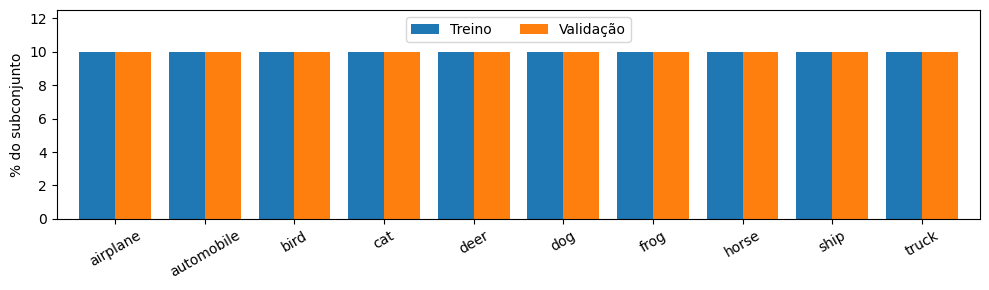

In [2]:
counts = pd.DataFrame({
    'Treino': np.bincount(y_train, minlength=len(CLASS_NAMES)),
    'Validação': np.bincount(y_val, minlength=len(CLASS_NAMES)),
}, index=pd.Index(CLASS_NAMES, name='Classe'))
display(counts)
ax = (counts / counts.sum()).mul(100).plot.bar(figsize=(10, 3), rot=30, width=0.8)
ax.set_ylim(0, 12.5)
ax.legend(loc='upper center', ncols=2)
plt.ylabel('% do subconjunto')
plt.xlabel('')
plt.tight_layout()
plt.show()

## Amostra visual do treino

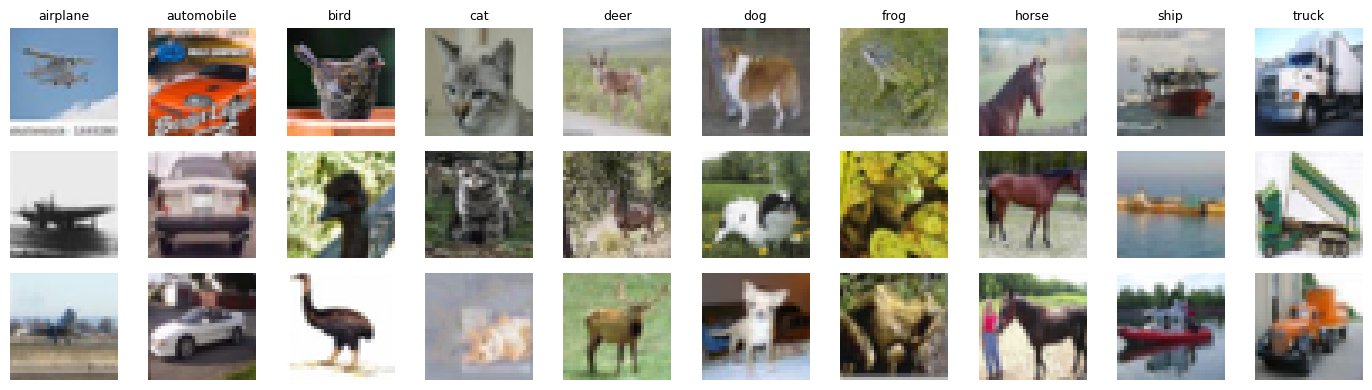

In [3]:
rng = np.random.default_rng(config['seed'])
fig, axes = plt.subplots(3, 10, figsize=(14, 4))
for cls, name in enumerate(CLASS_NAMES):
    samples = rng.choice(np.flatnonzero(y_train == cls), size=3, replace=False)
    for row, sample in enumerate(samples):
        ax = axes[row, cls]
        ax.imshow(x_train[sample], interpolation='nearest')
        ax.axis('off')
        if row == 0:
            ax.set_title(name, fontsize=9)
fig.tight_layout()
plt.show()

## Intensidade dos canais RGB no treino

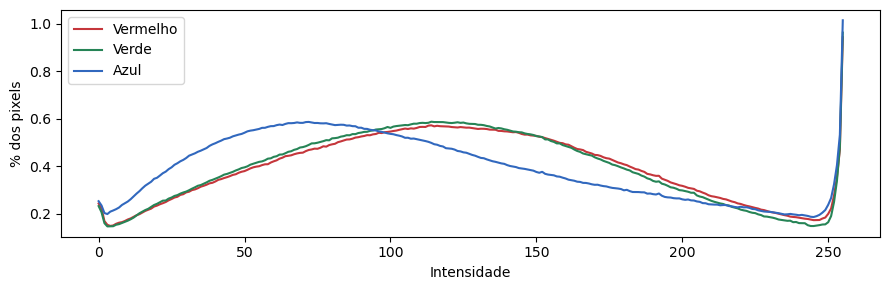

,Canal,Média,Desvio-padrão
0,Vermelho,125.23,62.99
1,Verde,122.95,62.10
2,Azul,113.88,66.72


In [4]:
levels = np.arange(256)
fig, ax = plt.subplots(figsize=(9, 3))
stats = []
for channel, color, name in zip(range(3), ('#c5363b', '#268456', '#3168be'),
                                ('Vermelho', 'Verde', 'Azul')):
    frequencies = np.bincount(x_train[..., channel].ravel(), minlength=len(levels))
    probabilities = frequencies / frequencies.sum()
    mean = levels @ probabilities
    std = np.sqrt((levels - mean)**2 @ probabilities)
    stats.append((name, mean, std))
    ax.plot(levels, probabilities * 100, color=color, label=name)
ax.set(xlabel='Intensidade', ylabel='% dos pixels')
ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame(stats, columns=['Canal', 'Média', 'Desvio-padrão']).round(2))

## Imagens idênticas
Cada assinatura representa os bytes RGB de uma imagem. A tabela quantifica repetições exatas e o cruzamento dos subconjuntos.

In [5]:
def count_images(images):
    return Counter(blake2b(image.tobytes(), digest_size=16).digest() for image in images)

train_counts = count_images(x_train)
val_counts = count_images(x_val)
shared = train_counts.keys() & val_counts.keys()
display(pd.Series({
    'Repetições além da primeira ocorrência no treino': len(x_train) - len(train_counts),
    'Repetições além da primeira ocorrência na validação': len(x_val) - len(val_counts),
    'Imagens distintas compartilhadas entre os splits': len(shared),
    'Imagens de validação com cópia no treino': sum(val_counts[key] for key in shared),
}, name='Quantidade').to_frame())

,Quantidade
Repetições além da primeira ocorrência no treino,0
Repetições além da primeira ocorrência na validação,0
Imagens distintas compartilhadas entre os splits,0
Imagens de validação com cópia no treino,0


## Implicações para a CNN

- Cada classe responde por 10% de cada subconjunto. A primeira CNN usa a mesma ponderação para todas as classes.
- Com resolução de 32 × 32, contornos, contexto e variação de enquadramento importam. A primeira CNN usa espelhamento e translação moderada no treino.
- A amostra mostra gatos e cães com enquadramentos parecidos e cervos e cavalos em fundos de vegetação. São pares para verificar na matriz de confusão.
- O modelo usa reescala fixa de 0 a 1. As estatísticas RGB acima descrevem os dados e ficam fora do ajuste de pré-processamento.
- A auditoria encontrou zero cópias exatas dentro de cada subconjunto e entre eles. Semelhanças após recorte, compressão ou mudanças de cor exigiriam outra análise.